This notebook is a replication of the Statistical Analysis tutorial on keypoint Moseq. Specifically found in the
*[kpms docs](https://keypoint-moseq.readthedocs.io/en/latest/analysis.html)*

In [1]:
import sys
from pathlib import Path

start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()

# Find the repo dir named 'syllable_generation'
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    raise RuntimeError("Could not find 'syllable_generation'")

# Make the package importable: add the *parent* of the repo to sys.path
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):  # both, for convenience
    if pth not in sys.path:
        sys.path.insert(0, pth)

# optional sanity check:
import importlib; importlib.import_module("syllable_generation")

<module 'syllable_generation' from '/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/__init__.py'>

In [2]:
# --- user-editable constants ---
PATH_PREFIX = "/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/"
SESSIONS_PKL = PATH_PREFIX + "loaders/jonathan_ifdn_sessions_w_sylls_full.pkl"
PROJECT_DIR = "/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project"
MODEL_NAME = "full-run"

USE_CPU = True           # set True to avoid reserving GPU for loading KPMS
OVERWRITE_PICKLE = True  # if False and file exists, we won't overwrite
PRINT_SAMPLE = True      # print a couple sample heads for inspection

In [3]:
import pandas as pd

import os
os.environ["JAX_PLATFORMS"] = "cpu"  # avoid grabbing the GPU for read-only ops

import keypoint_moseq as kpms

In [4]:
sessions = pd.read_pickle(SESSIONS_PKL)

In [9]:
out_path = Path(PROJECT_DIR) / MODEL_NAME / "index.csv"

def _grp(s):
    g = s.metadata.get("genotype")
    return g if isinstance(g, str) and g.strip() else "UNK"

rows = [{"name": s.results_dict_key, "group": _grp(s)} for s in sessions]
pd.DataFrame(rows, columns=["name", "group"]).to_csv(out_path, index=False)
out_path

PosixPath('/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/index.csv')

In [10]:
len(sessions)

19

In [11]:
moseq_df = kpms.compute_moseq_df(PROJECT_DIR, MODEL_NAME, smooth_heading=True)

In [13]:
moseq_df

,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,0,WT,True
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,1,WT,False
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,2,WT,False
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,3,WT,False
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,4,WT,False
...,...,...,...,...,...,...,...,...,...,...
4114930,Arena1234_CenterTopCamVid_2024-12-17T12_37_40_...,70.409914,128.542315,-1.604544,1.043472,86.171672,54,143807,UNK,False
4114931,Arena1234_CenterTopCamVid_2024-12-17T12_37_40_...,68.178179,126.800341,-1.516835,0.849673,84.932943,54,143808,UNK,False
4114932,Arena1234_CenterTopCamVid_2024-12-17T12_37_40_...,66.674209,124.029043,-1.488353,0.645352,94.592898,54,143809,UNK,False
4114933,Arena1234_CenterTopCamVid_2024-12-17T12_37_40_...,66.683953,121.307837,-1.488353,0.433392,81.636705,54,143810,UNK,False


In [16]:
stats_df = kpms.compute_stats_df(
    PROJECT_DIR,
    MODEL_NAME,
    moseq_df,
    min_frequency=0.005,  # threshold frequency for including a syllable in the dataframe
    groupby=["group", "name"],  # column(s) to group the dataframe by
    fps=30,
)  # frame rate of the video from which keypoints were inferred

stats_df


,group,name,syllable,heading_mean,heading_std,heading_min,heading_max,angular_velocity_mean,angular_velocity_std,angular_velocity_min,angular_velocity_max,velocity_px_s_mean,velocity_px_s_std,velocity_px_s_min,velocity_px_s_max,frequency,duration
0,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,0,0.835115,0.879796,-3.073545,2.495611,-0.034520,0.844700,-1.662716,9.867660,41.255331,24.808889,3.157366,143.232262,0.009612,0.350000
1,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,3,0.568782,0.626229,-2.878967,2.436485,-0.099113,0.680296,-10.038555,8.832326,25.732856,14.346365,0.423801,115.186053,0.012384,1.535323
2,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,4,0.069007,1.691452,-3.132559,3.131740,0.745582,6.277020,-188.269934,3.504616,53.557775,29.931473,1.015170,171.884331,0.074307,0.301575
3,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,8,0.617911,2.149403,-3.141322,3.141064,-0.040935,12.172428,-188.309915,188.293243,76.473364,34.260537,0.343105,180.359612,0.040296,0.585474
4,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,9,-0.241524,1.491122,-3.103678,3.132871,-0.079608,6.585171,-188.102217,2.352206,27.322382,15.208797,2.137075,103.131013,0.007763,0.652381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,87,-1.053545,1.668922,-3.140907,3.131579,-0.014636,5.426479,-188.229740,188.004924,26.584077,14.814130,0.526303,104.950163,0.005887,5.018750
888,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,90,1.289445,1.085032,-3.125642,3.140276,-0.066779,2.860847,-2.001617,188.127567,28.140958,16.066738,0.344165,138.416724,0.026490,2.029630
889,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,93,0.983276,1.312058,-3.132945,3.137682,-0.398826,9.795543,-188.093196,188.078849,32.164967,17.087778,1.268906,99.822783,0.009198,0.493333
890,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,95,-0.365513,1.567173,-3.126834,3.139459,0.064531,10.450875,-188.071754,187.181371,27.656806,14.691840,0.547681,104.273111,0.036424,0.433838


/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/categorical.py:1202: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.

/home/fsp585/miniforge3/envs/kpms/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.

/hom

No significant syllables found.
Saved figure to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/figures/frequency_stat_stats.png


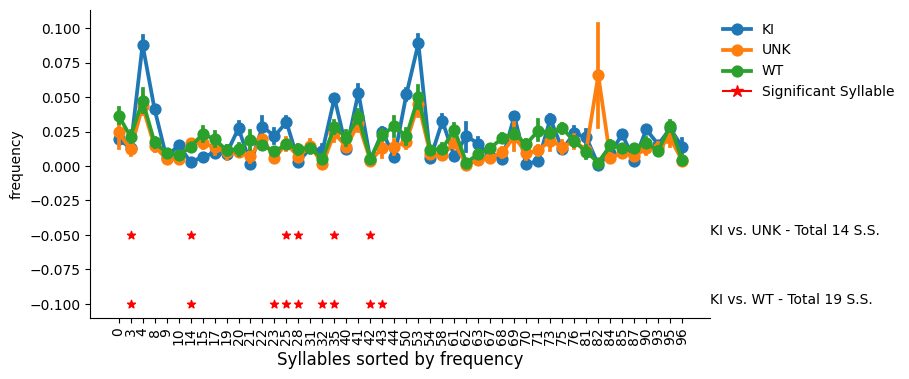

In [18]:
kpms.plot_syll_stats_with_sem(
    stats_df,
    PROJECT_DIR,
    MODEL_NAME,
    plot_sig=True,  # whether to mark statistical significance with a star
    thresh=0.05,  # significance threshold
    stat="frequency",  # statistic to be plotted (e.g. 'duration' or 'velocity_px_s_mean')
    order="stat",  # order syllables by overall frequency ("stat") or degree of difference ("diff")
    ctrl_group="a",  # name of the control group for statistical testing
    exp_group="b",  # name of the experimental group for statistical testing
    figsize=(8, 4),  # figure size
    groups=stats_df["group"].unique(),  # groups to be plotted
);


Group(s): KI, UNK, WT
Saved figure to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/figures/transition_matrices.png


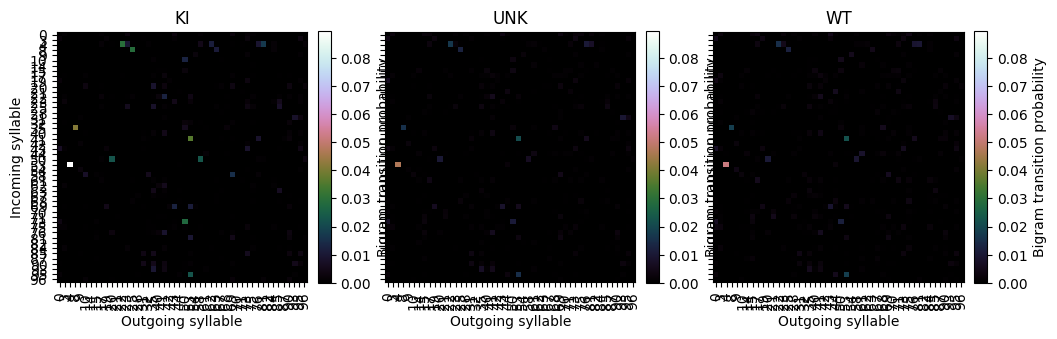

In [19]:
normalize = "bigram"  # normalization method ("bigram", "rows" or "columns")

trans_mats, usages, groups, syll_include = kpms.generate_transition_matrices(
    PROJECT_DIR,
    MODEL_NAME,
    normalize=normalize,
    min_frequency=0.005,  # minimum syllable frequency to include
)

kpms.visualize_transition_bigram(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    syll_include,
    normalize=normalize,
    show_syllable_names=True,  # label syllables by index (False) or index and name (True)
)


Saved figure to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/figures/transition_graphs.png


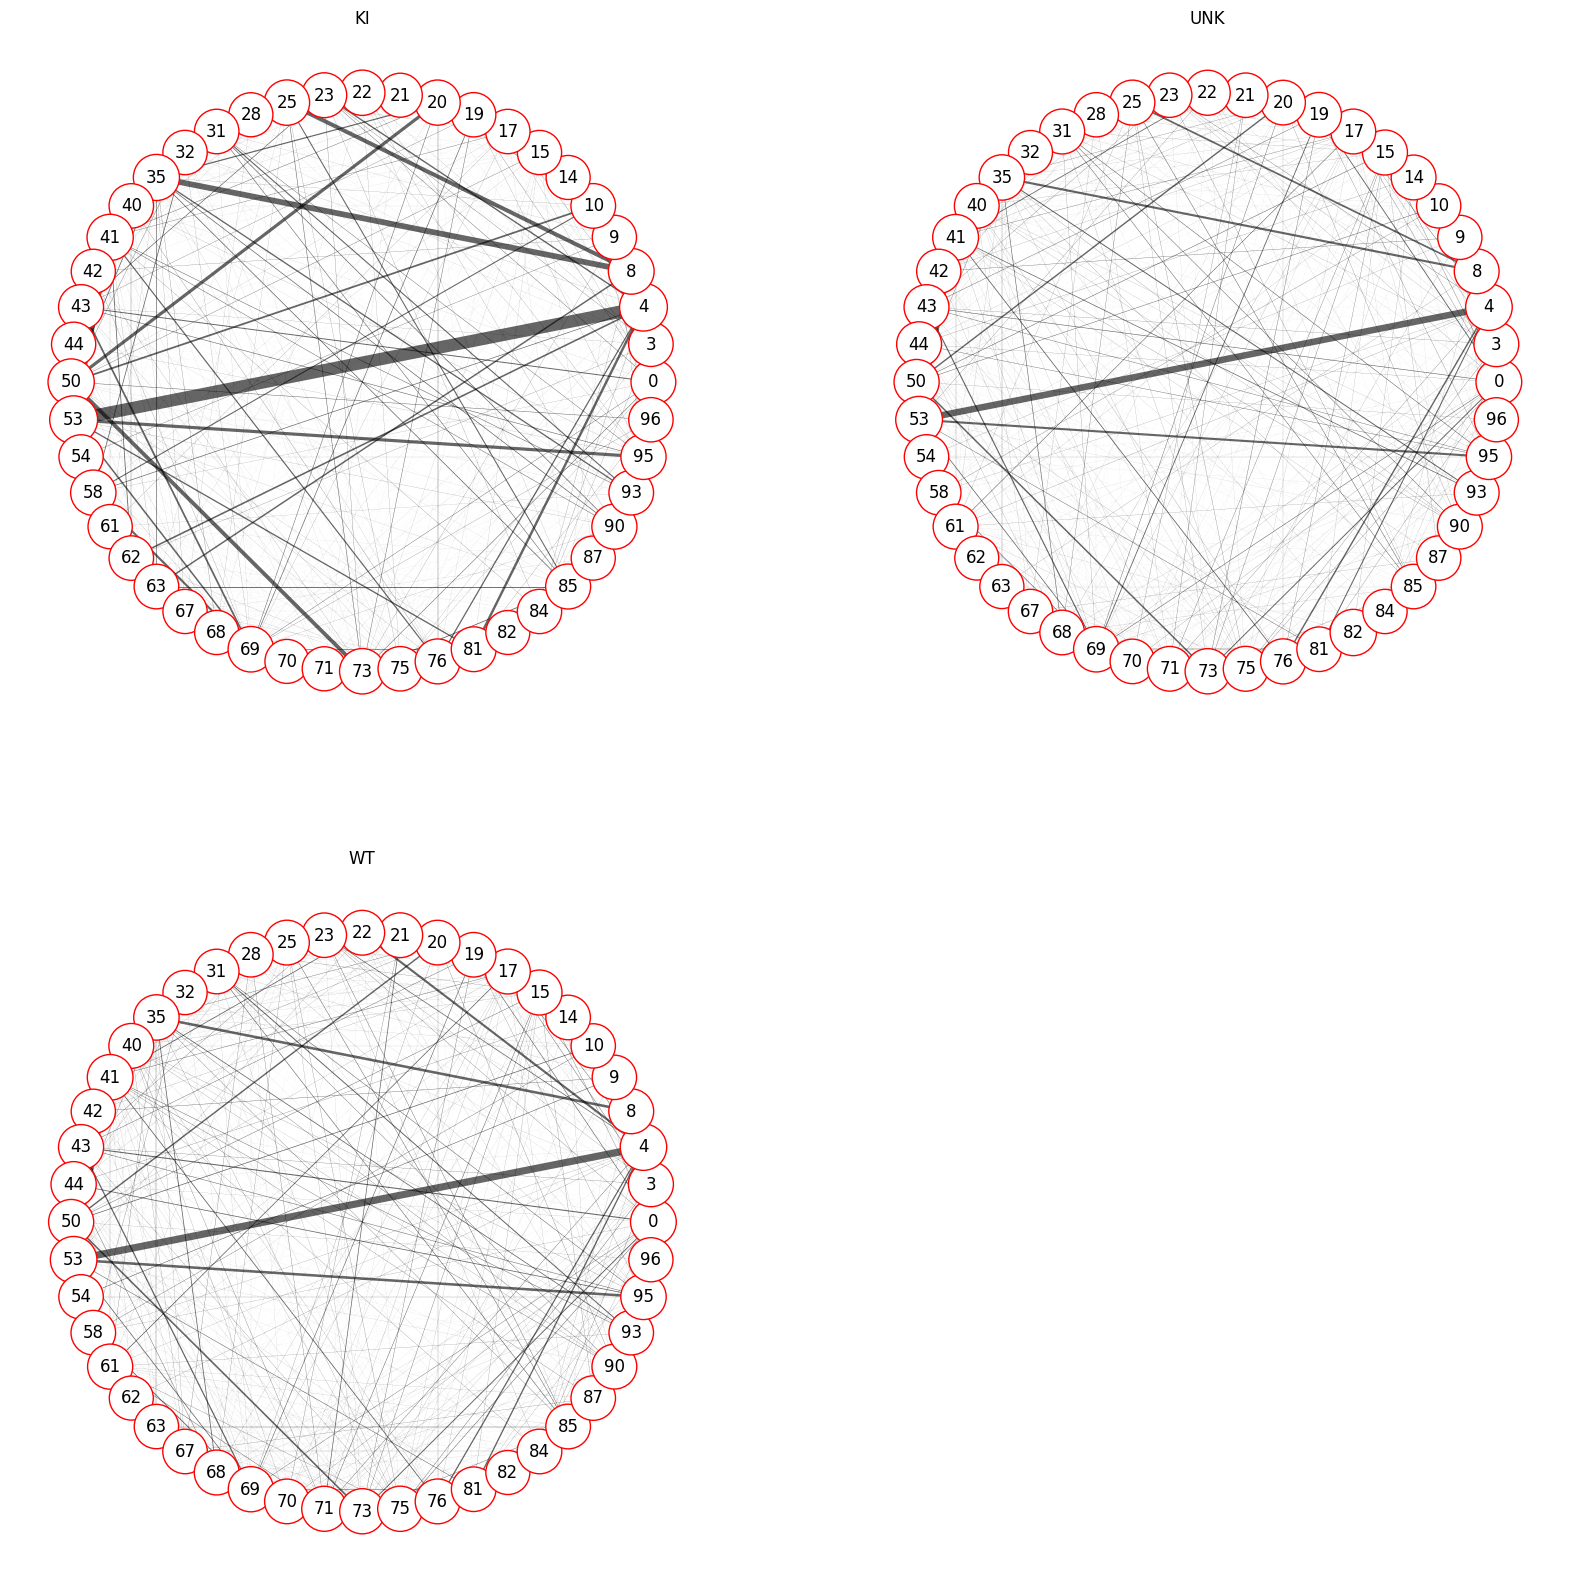

In [20]:
kpms.plot_transition_graph_group(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    usages,
    syll_include,
    layout="circular",  # transition graph layout ("circular" or "spring")
    show_syllable_names=False,  # label syllables by index (False) or index and name (True)
)


Saved figure to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/syllabizers/keypoint_moseq_syll/demo_project/full-run/figures/transition_graphs_diff.png


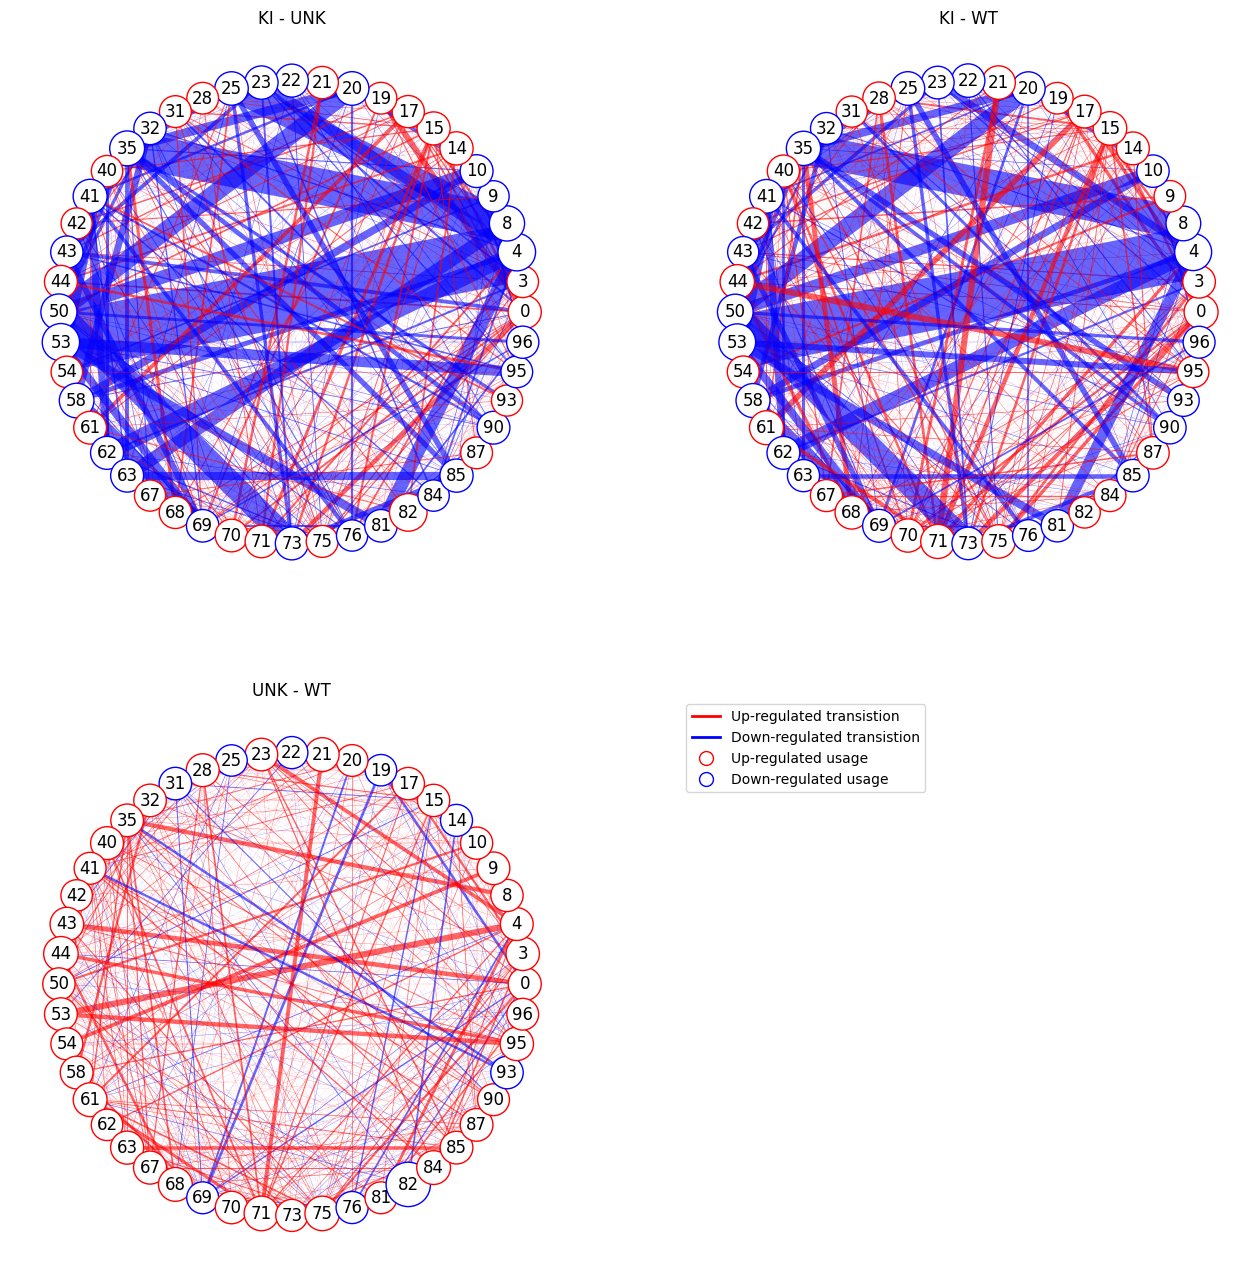

In [21]:
kpms.plot_transition_graph_difference(
    PROJECT_DIR, MODEL_NAME, groups, trans_mats, usages, syll_include, layout="circular"
)  # transition graph layout ("circular" or "spring")
